# Model Evaluation

In [12]:
import sys
sys.path.append('..')

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

from src.utils import creating_datasets
from src.model import SimplestCNN, MediumCNN, DeepCNN
from src.evaluation import (get_predictions, get_predictions_with_probabilities,
                           plot_confusion_matrix, print_classification_metrics,
                           plot_roc_curves, analyze_misclassifications, plot_misclassified_samples)

device = torch.device('cpu')

class_names = ['Paper', 'Rock', 'Scissors']

## Load Best Model

Load the model that performed best in the comparison.

In [13]:
train_dataset, val_dataset, test_dataset = creating_datasets(
    root_dir='../data/raw',
    test_size=0.2,
    val_size=0.1,
    random_state=42
)

test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

model = DeepCNN(num_classes=3, dropout_rate=0.5).to(device)
model.load_state_dict(torch.load('../models/deep_cnn.pth', map_location=device))
model.eval()

DeepCNN(
  (conv1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv3): Sequential(
    (0): Conv2d(64, 128, ke

## Get Predictions

In [14]:
y_pred, y_probabilities, y_true = get_predictions_with_probabilities(model, test_loader, device)
print(f"Total test samples: {len(y_true)}")

Total test samples: 438


## Confusion Matrix

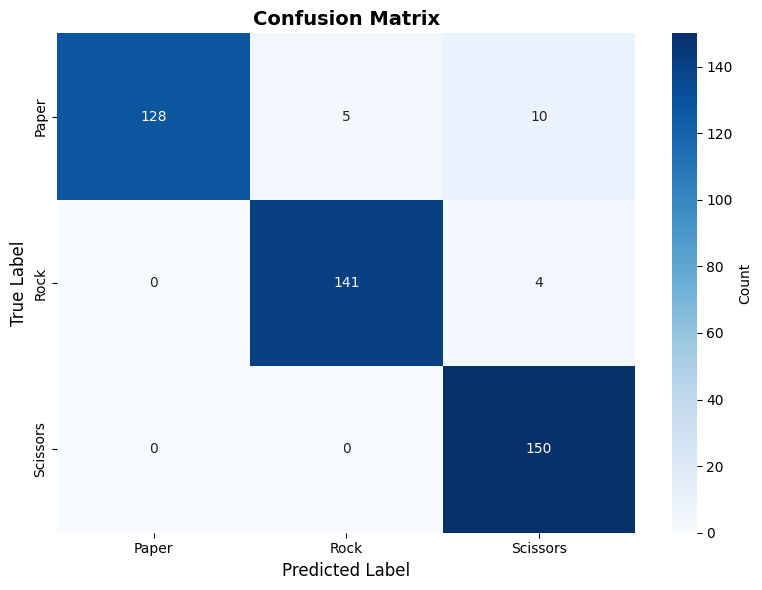

In [15]:
plot_confusion_matrix(y_true, y_pred, class_names, save_path='../reports/figures/confusion_matrix.png')

## Classification Metrics

In [16]:
print_classification_metrics(y_true, y_pred, class_names)

              precision    recall  f1-score   support

       Paper     1.0000    0.8951    0.9446       143
        Rock     0.9658    0.9724    0.9691       145
    Scissors     0.9146    1.0000    0.9554       150

    accuracy                         0.9566       438
   macro avg     0.9601    0.9558    0.9564       438
weighted avg     0.9594    0.9566    0.9564       438

  Precision: 0.9594
  Recall:    0.9566
  F1-Score:  0.9564


## Per-Class Accuracy

In [17]:
from sklearn.metrics import accuracy_score
import numpy as np

for i, class_name in enumerate(class_names):
    mask = np.array(y_true) == i
    class_accuracy = accuracy_score(np.array(y_true)[mask], np.array(y_pred)[mask])
    print(f"{class_name}: {class_accuracy:.4f}")

Paper: 0.8951
Rock: 0.9724
Scissors: 1.0000


## Misclassification Analysis

In [18]:
misclassified = np.where(np.array(y_true) != np.array(y_pred))[0]
print(f"Total misclassified: {len(misclassified)} out of {len(y_true)} ({len(misclassified)/len(y_true)*100:.2f}%)")

if len(misclassified) > 0:
    for i in range(3):
        for j in range(3):
            if i != j:
                count = np.sum((np.array(y_true) == i) & (np.array(y_pred) == j))
                if count > 0:
                    print(f"{class_names[i]} - {class_names[j]}: {count}")

Total misclassified: 19 out of 438 (4.34%)
Paper - Rock: 5
Paper - Scissors: 10
Rock - Scissors: 4


## ROC Curves


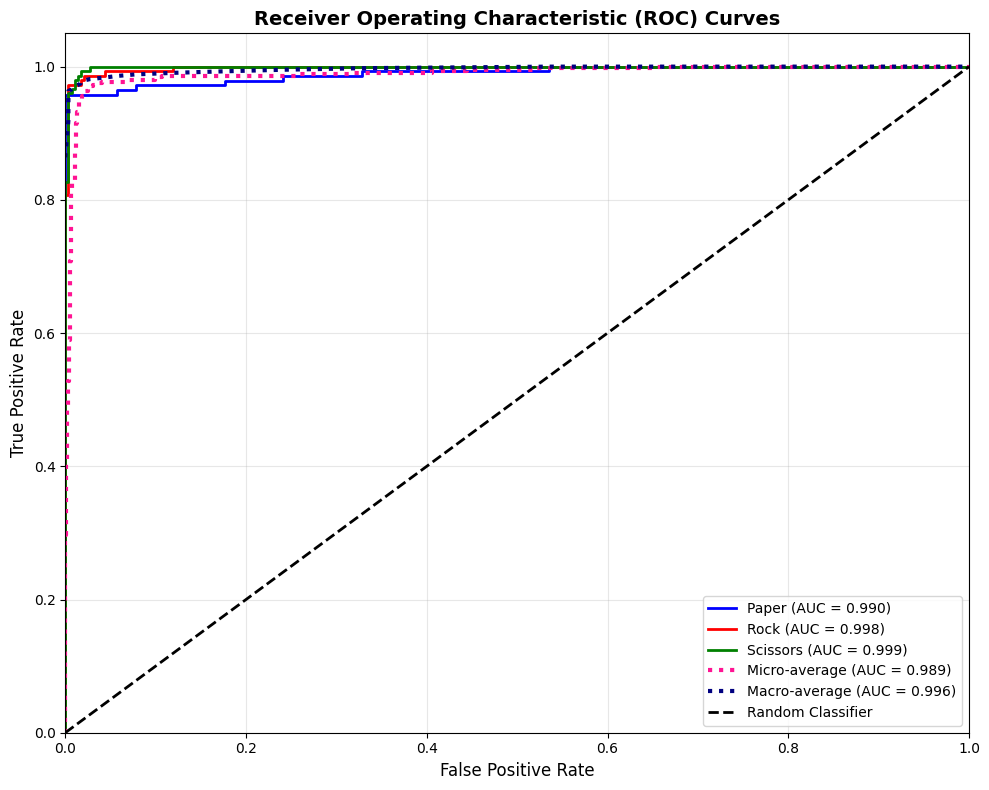


AUC Scores:
  Paper: 0.9901
  Rock: 0.9980
  Scissors: 0.9990
  Micro: 0.9888
  Macro: 0.9964


In [19]:
roc_auc = plot_roc_curves(y_true, y_probabilities, class_names, 
                          save_path='../reports/figures/roc_curves.png')

print("\nAUC Scores:")
for key, value in roc_auc.items():
    if isinstance(key, int):
        print(f"  {class_names[key]}: {value:.4f}")
    else:
        print(f"  {key.capitalize()}: {value:.4f}")

## Detailed Misclassification Analysis

In [20]:
misclass_info = analyze_misclassifications(y_true, y_pred, y_probabilities, class_names)

Total samples: 438
Misclassified: 19 (4.34%)
Correctly classified: 419 (95.66%)
  Paper → Rock: 5 samples
  Paper → Scissors: 10 samples
  Rock → Scissors: 4 samples

  Correct predictions - Avg confidence: 0.9803
                       Min confidence: 0.5479
                       Max confidence: 1.0000
  Wrong predictions   - Avg confidence: 0.8272
                       Min confidence: 0.4915
                       Max confidence: 1.0000

Per-Class Misclassification Rate:
  Paper: 15/143 (10.49%)
  Rock: 4/145 (2.76%)
  Scissors: 0/150 (0.00%)


## Visualize Misclassified Examples

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.8901961].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.99215686..0.79607844].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.9764706..0.8509804].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.9843137..0.6862745].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.67058825].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.94509804..0.9372549].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.6862745].

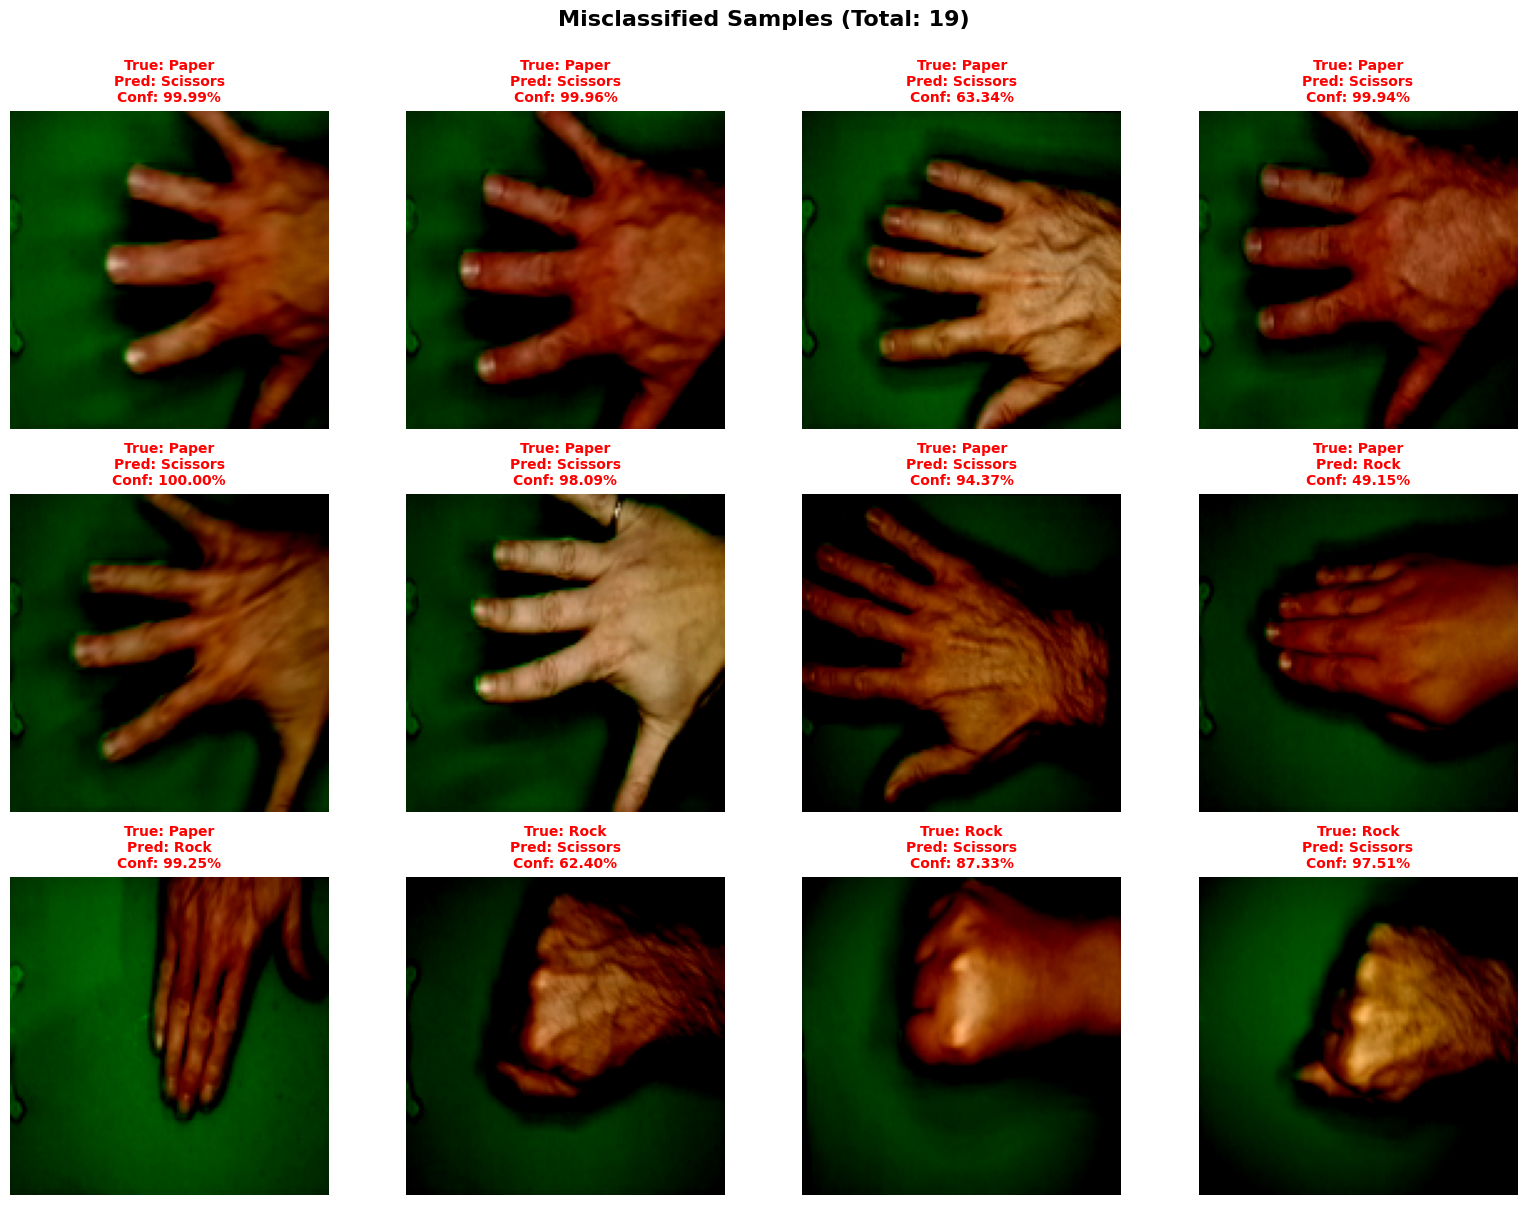

In [21]:
test_images = []
for inputs, _ in test_loader:
    test_images.append(inputs.numpy())
test_images = np.concatenate(test_images, axis=0)

plot_misclassified_samples(test_images, y_true, y_pred, y_probabilities, 
                          class_names, max_samples=12,
                          save_path='../reports/figures/misclassified_samples.png')